# PV fault detection — one XGBoost model for any string-level PV system (v6)
**Classes:** 0 normal · 1 partial shading · 2 dirt · 3 open circuit · 4 short circuit · 5 degradation (high series resistance)

**Training data:** a *library* of 90 randomly designed PV systems (simulated with `pv_simulator_v3.py`):
small panels without bypass diodes, 36-cell panels with 2 bypass diodes, 60/72-cell panels with 3 bypass diodes;
1–20 modules per string; 1–3 strings in parallel; new to old/low-quality modules; 35 % of strings mix 2–3 module models.
Ratings are drawn from typical market ranges; systems too similar to a test system are removed.
Faults range from a detection threshold (a noticeable loss) up to large faults; dirt comes as a dust film (3–25 % loss) or as splashed dirt
(light film + heavy blotches).

**Test systems — never used for training:**
- System 1: paper's 2 × 10 W test modules (series and parallel), no bypass diodes — 1002 rows
- System 2: paper's 7 × 200 W rooftop string — 402 rows
- System 3: 10 × 330 W residential string — 402 rows

**Weather:** uniform over 250–1000 W/m² and 15–40 °C for every test system and every class (library: 200–1050 W/m², 10–45 °C).

**Rules:** every score is on readings the model never saw. XGBoost settings are chosen by cross-validation on the library only.
*Commissioning* = 5 labelled readings per class from a new system added to training (weight 5); scored on that system's other readings.

Runtime on Colab CPU: about 30–40 minutes.

In [1]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    !pip -q install xgboost shap
    from google.colab import drive
    drive.mount('/content/drive')
    WORK_DIR = '/content/drive/MyDrive/PV_Project/PV_v6'     # <-- folder with this notebook's files
else:
    WORK_DIR = os.environ.get('PV_DIR', '.')
os.chdir(WORK_DIR); sys.path.insert(0, WORK_DIR)
os.makedirs('figures', exist_ok=True); os.makedirs('models', exist_ok=True)

In [2]:
import json, warnings
warnings.filterwarnings('ignore')
import glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GroupKFold, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from xgboost import XGBClassifier
import shap
import pv_simulator_v3 as P, stress_test as ST

LABELS = P.CLASSES; K = len(LABELS); K_SHOTS = 5; SYS = (1, 2, 3)
T = {1: pd.read_csv('data_v6/S1_6class_1002.csv'), 2: pd.read_csv('data_v6/S2_6class_402.csv'),
     3: pd.read_csv('data_v6/S3_6class_402.csv')}
LIB = pd.read_csv(sorted(glob.glob('data_v6/library_6class_*.csv'))[0]); LIBSYS = pd.read_csv('data_v6/library_systems.csv')
print(f'Library: {len(LIBSYS)} systems, {len(LIB)} readings')
print(LIBSYS.groupby(['kind', 'parallel']).size().rename('systems').to_string())
for s, d in T.items(): print(f'Test System {s}: {len(d)} readings, per class {d.Fault.value_counts().sort_index().tolist()}')

Library: 90 systems, 5940 readings
kind   parallel
36c    1            9
       2            2
       3            2
small  1            2
       2            6
       3            5
std    1           32
       2           17
       3           15
Test System 1: 1002 readings, per class [167, 167, 167, 167, 167, 167]
Test System 2: 402 readings, per class [67, 67, 67, 67, 67, 67]
Test System 3: 402 readings, per class [67, 67, 67, 67, 67, 67]


### Model inputs (22) — one I-V sweep + irradiance + temperature + the number of parallel strings
| Group | Inputs |
|---|---|
| Paper's 4 features | Voc/MaxVoc, Isc/MaxIsc, G/1000, AT/50 |
| I-V tracer | Vmp/MaxVoc, Imp/MaxIsc, FF |
| Physics ratios | Isc/G, Vmp/Voc, Imp/Isc, Imp/G |
| Curve shape | Rs_n (slope near Voc = series resistance), Rsh_n (slope near Isc), Steps (number of power peaks = bypass diodes switching on) |
| Measured ÷ expected-healthy | Voc_r, Isc_r, Vmp_r, Imp_r, FF_r, P_r, Rs_r — the expected value comes from the system's datasheet at the measured sunlight and temperature |
| Topology | Strings — number of parallel strings (entered once by the installer, like MaxVoc) |

In [3]:
SPACE = {'n_estimators': [200, 400, 600], 'max_depth': [3, 4, 6], 'learning_rate': [0.05, 0.1, 0.2],
         'subsample': [0.7, 0.85, 1.0], 'colsample_bytree': [0.6, 0.8, 1.0], 'min_child_weight': [1, 3, 5]}
X0, y0 = P.inputs(LIB), LIB.Fault
# settings chosen by cross-validation on the library, keeping whole systems together in each fold (GroupKFold)
search = RandomizedSearchCV(XGBClassifier(random_state=0, n_jobs=-1), SPACE, n_iter=15, cv=GroupKFold(5), random_state=0)
search.fit(X0, y0, groups=LIB.System); PARAMS = search.best_params_
print('Settings:', PARAMS, f'  (cross-validated accuracy on unseen LIBRARY systems: {search.best_score_:.3f})')
source = XGBClassifier(random_state=0, n_jobs=-1, **PARAMS).fit(X0, y0)

def show_cm(cm, title, fname):
    fig, ax = plt.subplots(figsize=(6.2, 5.2)); ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(K)); ax.set_xticklabels(LABELS, rotation=40, ha='right'); ax.set_yticks(range(K)); ax.set_yticklabels(LABELS)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(title); fig.tight_layout(); fig.savefig(f'figures/{fname}', dpi=150); plt.show()

def commission(s, d, draws=5, base=(X0, y0)):
    """Add K_SHOTS readings per class of system s (weight 5); score on its other readings. Returns accuracies, summed confusion, last model."""
    acc, cm = [], np.zeros((K, K), int)
    for draw in range(draws):
        shots = d.groupby('Fault', group_keys=False).sample(K_SHOTS, random_state=500 + draw); rest = d.drop(shots.index)
        m = XGBClassifier(random_state=draw, n_jobs=-1, **PARAMS).fit(pd.concat([base[0], P.inputs(shots)]), pd.concat([base[1], shots.Fault]),
                                                                   sample_weight=np.r_[np.ones(len(base[0])), np.full(len(shots), 5.0)])
        pred = m.predict(P.inputs(rest)); acc.append(accuracy_score(rest.Fault, pred)); cm += confusion_matrix(rest.Fault, pred, labels=range(K))
    return acc, cm, m

Settings: {'subsample': 0.85, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.2, 'colsample_bytree': 0.8}   (cross-validated accuracy on unseen LIBRARY systems: 0.977)


## A. Main result: trained on the library only, tested on Systems 1–3

System 1 done


System 2 done


System 3 done


                             System 1  System 2  System 3
zero-shot                       0.967     0.980     0.983
after 5 readings per class      0.974     0.992     0.991
after 5 readings (std)          0.004     0.004     0.004
within-system (upper bound)     0.987     0.992     0.984


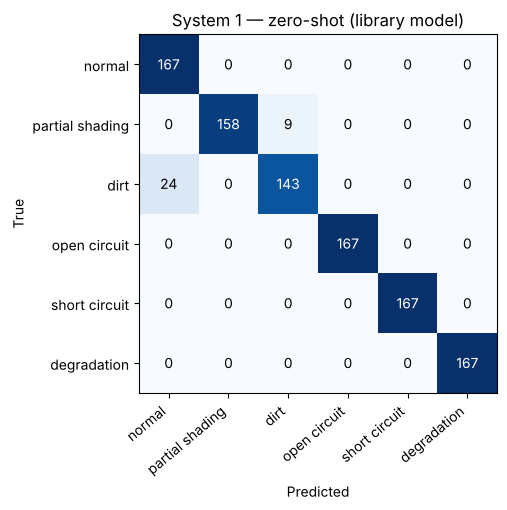

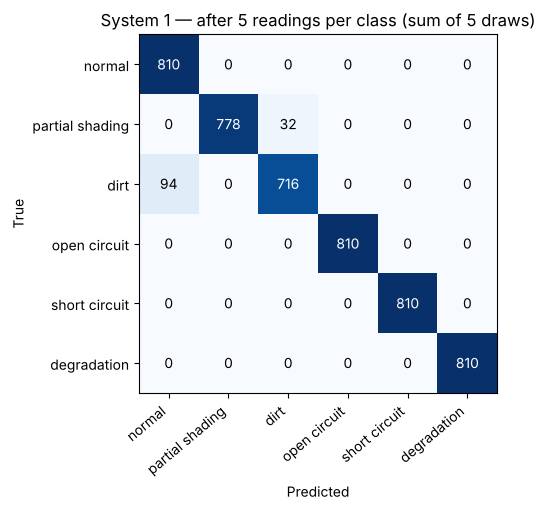

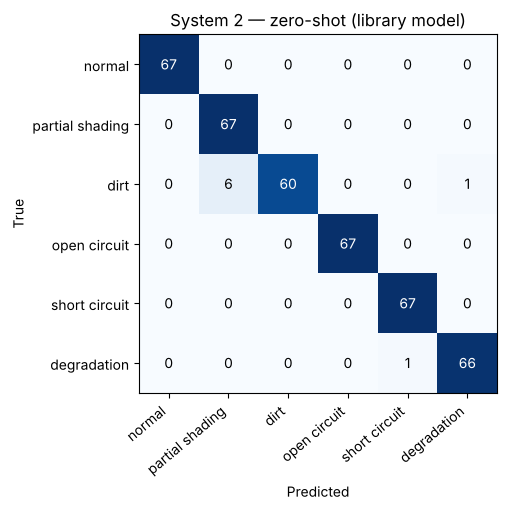

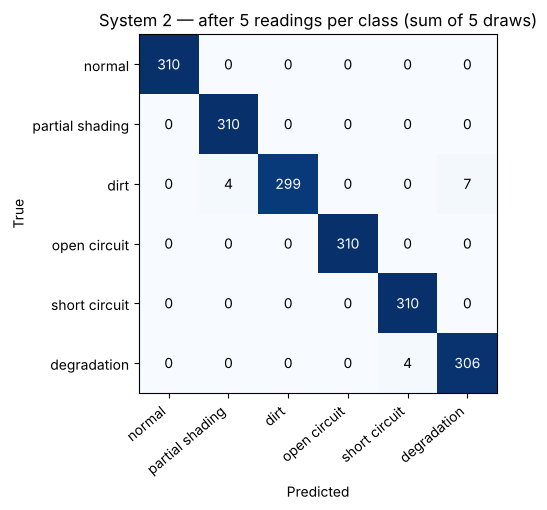

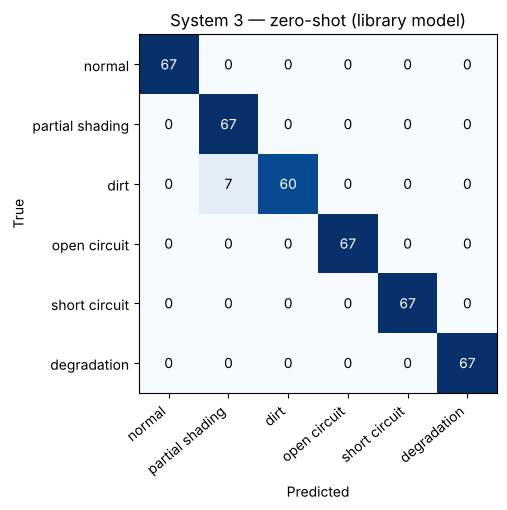

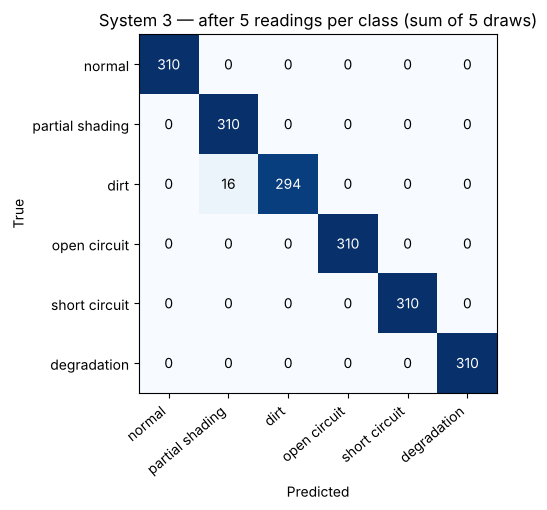


Recall per class after commissioning:
                 System 1  System 2  System 3
normal              1.000     1.000     1.000
partial shading     0.960     1.000     1.000
dirt                0.884     0.965     0.948
open circuit        1.000     1.000     1.000
short circuit       1.000     1.000     1.000
degradation         1.000     0.987     1.000


In [4]:
res, CMZ, CMC, ADAPTED = {}, {}, {}, {}
for s, d in T.items():
    pz = source.predict(P.inputs(d)); res[(s, 'zero-shot')] = accuracy_score(d.Fault, pz); CMZ[s] = confusion_matrix(d.Fault, pz, labels=range(K))
    acc, CMC[s], ADAPTED[s] = commission(s, d); res[(s, 'after 5 readings per class')] = np.mean(acc); res[(s, 'after 5 readings (std)')] = np.std(acc)
    a = []
    for run in range(3):
        tr, te = train_test_split(d.index, test_size=0.2, stratify=d.Fault, random_state=run)
        a.append(accuracy_score(d.Fault[te], XGBClassifier(random_state=run, n_jobs=-1, **PARAMS).fit(P.inputs(d.loc[tr]), d.Fault[tr]).predict(P.inputs(d.loc[te]))))
    res[(s, 'within-system (upper bound)')] = np.mean(a)
    print(f'System {s} done', flush=True)
tabA = pd.Series(res).unstack(0).round(3); tabA.columns = [f'System {c}' for c in tabA.columns]
tabA = tabA.reindex(['zero-shot', 'after 5 readings per class', 'after 5 readings (std)', 'within-system (upper bound)']); print(tabA.to_string())
for s in SYS:
    show_cm(CMZ[s], f'System {s} — zero-shot (library model)', f'cm_system{s}_zeroshot.png')
    show_cm(CMC[s], f'System {s} — after 5 readings per class (sum of 5 draws)', f'cm_system{s}_commissioned.png')
rec = pd.DataFrame({f'System {s}': np.diag(CMC[s]) / CMC[s].sum(1) for s in SYS}, index=LABELS).round(3)
print('\nRecall per class after commissioning:'); print(rec.to_string())

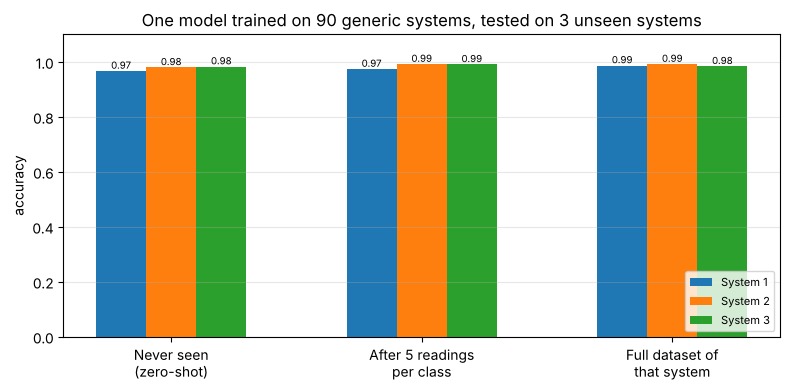

In [5]:
fig, ax = plt.subplots(figsize=(8, 4)); cols = ['zero-shot', 'after 5 readings per class', 'within-system (upper bound)']; w = 0.2
for i, s in enumerate(SYS):
    b = ax.bar(np.arange(3) + (i - 1) * w, [tabA.loc[c, f'System {s}'] for c in cols], w, label=f'System {s}'); ax.bar_label(b, fmt='%.2f', fontsize=7)
ax.set_xticks(range(3)); ax.set_xticklabels(['Never seen\n(zero-shot)', 'After 5 readings\nper class', 'Full dataset of\nthat system'])
ax.set_ylim(0, 1.1); ax.set_ylabel('accuracy'); ax.set_title('One model trained on 90 generic systems, tested on 3 unseen systems')
ax.legend(loc='lower right', fontsize=8); ax.grid(axis='y', alpha=.3); fig.tight_layout(); fig.savefig('figures/main_result.png', dpi=150); plt.show()

## B. Does adding System 1 (the paper's training system) to the library help the other systems?

In [6]:
Xs1 = pd.concat([X0, P.inputs(T[1])]); ys1 = pd.concat([y0, T[1].Fault])
m_s1 = XGBClassifier(random_state=0, n_jobs=-1, **PARAMS).fit(Xs1, ys1)
cmpB = pd.DataFrame({'library only': [tabA.loc['zero-shot', f'System {s}'] for s in (2, 3)],
                     'library + System 1': [accuracy_score(T[s].Fault, m_s1.predict(P.inputs(T[s]))) for s in (2, 3)]},
                    index=['System 2 zero-shot', 'System 3 zero-shot']).round(3)
print(cmpB.to_string())

                    library only  library + System 1
System 2 zero-shot         0.980               0.983
System 3 zero-shot         0.983               0.988


## C. Troubleshooting: how the library and inputs got here
| Version | Change | Why |
|---|---|---|
| v6a | first library: new-ish modules, identical modules per string, dirt = 3–15 % film | — |
| v6b | + older / low-quality modules, + 35 % mixed-module strings, + splashed dirt (light film + heavy blotches) | System 2 (the paper's real rooftop string) has old, mismatched modules and splashed dirt; its zero-shot was lowest |
| v6c (final) | + dust film up to 25 % loss, + input **number of parallel strings** (22 inputs) | stress test: 20 % dust was called shading on every system; on System 2, 10–20 % corrosion was called short circuit |

Why the parallel-string count matters: in a **parallel** array the healthy strings hold the voltage, so a string with shorted bypass diodes
shows *Voc unchanged + higher apparent series resistance*, much like corrosion. In a **single** string a short always lowers Voc.
Without knowing the topology the model mixed the two. The installer knows the number of strings, as they know MaxVoc and MaxIsc.
Changes were physics coverage, not System 2's parameter values; look-alikes of the test systems are still removed. Same settings, same test data:

In [7]:
def version_scores(lib_dir, topology):
    L = pd.read_csv(f'{lib_dir}/library_6class_5940.csv')
    if topology and 'Strings' not in L: L = L.merge(pd.read_csv(f'{lib_dir}/library_systems.csv')[['id', 'parallel']].rename(columns={'id': 'System', 'parallel': 'Strings'}), on='System')
    XL, yL = P.inputs(L, topology), L.Fault; m = XGBClassifier(random_state=0, n_jobs=-1, **PARAMS).fit(XL, yL); out = {}
    for s, d in T.items():
        acc = []
        for draw in range(3):
            shots = d.groupby('Fault', group_keys=False).sample(K_SHOTS, random_state=500 + draw); rest = d.drop(shots.index)
            mm = XGBClassifier(random_state=draw, n_jobs=-1, **PARAMS).fit(pd.concat([XL, P.inputs(shots, topology)]), pd.concat([yL, shots.Fault]),
                                                                        sample_weight=np.r_[np.ones(len(XL)), np.full(len(shots), 5.0)])
            acc.append(accuracy_score(rest.Fault, mm.predict(P.inputs(rest, topology))))
        out[f'System {s}'] = {'zero-shot': accuracy_score(d.Fault, m.predict(P.inputs(d, topology))), 'after 5 readings': np.mean(acc)}
    return out
rowsC = {}
for name, lib_dir in [('v6a', 'v6a_first_library'), ('v6b', 'v6b_library')]:
    for s, v in version_scores(lib_dir, topology=False).items():
        for k, a in v.items(): rowsC.setdefault(f'{name} {k}', {})[s] = a
for s in SYS:
    rowsC.setdefault('v6c (final) zero-shot', {})[f'System {s}'] = tabA.loc['zero-shot', f'System {s}']
    rowsC.setdefault('v6c (final) after 5 readings', {})[f'System {s}'] = tabA.loc['after 5 readings per class', f'System {s}']
tabC = pd.DataFrame(rowsC).T.round(3); tabC.to_csv('results_v6_library_versions.csv'); print(tabC.to_string())

                              System 1  System 2  System 3
v6a zero-shot                    0.941     0.741     0.891
v6a after 5 readings             0.971     0.929     0.916
v6b zero-shot                    0.951     0.915     0.963
v6b after 5 readings             0.968     0.935     0.968
v6c (final) zero-shot            0.967     0.980     0.983
v6c (final) after 5 readings     0.974     0.992     0.991


### Earlier steps (v4 → v5), for the report
Systems 2–3, 6 classes, paper's weather ranges (v5 notebook, section B):

| Step | S2 zero-shot | S3 zero-shot | S2 after 5 readings | S3 after 5 readings |
|---|---|---|---|---|
| 1. I-V + physics ratios, trained on System 1 | 0.470 | 0.500 | 0.926 | 0.902 |
| 2. + curve-shape features | 0.371 | 0.500 | 0.948 | 0.948 |
| 3. + expected-healthy ratios | 0.537 | 0.582 | 0.962 | 0.933 |
| 4. + 12 generic strings in training | 0.876 | 0.970 | 0.984 | 0.982 |

v6 replaces step 4's 12 single strings by a 90-system library (with and without bypass diodes, 1–3 parallel strings) and keeps every test system out of training.

## D. Stress test: faults made like in the demo (chosen size, random weather), 30 readings each
Fraction classified correctly, before and after commissioning. Faults below the detection threshold are expected to be hard:

In [8]:
for k, v in ST.THRESHOLD_NOTE.items(): print(f'  detection threshold, {k}: {v}')
stress = ST.run({'zero-shot': {s: source for s in SYS}, 'after 5 readings': ADAPTED}, systems=SYS, n=30)
stress.to_csv('results_v6_stress_test.csv', index=False)
pd.set_option('display.width', 220)
for s in SYS:
    print(f'\n=== System {s} ==='); print(stress[stress.system == s].drop(columns=['system']).round(2).to_string(index=False))

  detection threshold, partial shading: >= 2 substrings and >= 5 % of the string's substrings (no-bypass modules: >= 1 cell)
  detection threshold, dirt: >= 3 % loss over the panels
  detection threshold, short circuit: >= 4 % of the string's substrings (>= 1)
  detection threshold, degradation: >= 7 % extra series resistance (of Vmp/Imp)



=== System 1 ===
                  fault      true_class  zero-shot zero-shot: main mistake  after 5 readings after 5 readings: main mistake
                healthy          normal       1.00                                      1.00                               
               dust 2 %            dirt       0.03                  normal              0.07                         normal
               dust 5 %            dirt       1.00                                      1.00                               
              dust 10 %            dirt       1.00                                      1.00                               
              dust 20 %            dirt       1.00                                      1.00                               
               cut wire    open circuit       1.00                                      1.00                               
 1 shorted bypass diode   short circuit       1.00                                      1.00                      

## E. Does the result depend on the particular simulated test data? (2 new test datasets per system)

In [9]:
rob = []
for seed in (1, 2):
    row = {'seed': seed}
    for s in (2, 3):
        nd = P.generate(s, 300, 9000 + 10 * s + seed)
        row[f'S{s} zero-shot'] = accuracy_score(nd.Fault, source.predict(P.inputs(nd)))
        row[f'S{s} 5 readings'] = np.mean(commission(s, nd, draws=2)[0])
    rob.append(row); print({k: round(v, 3) for k, v in row.items()}, flush=True)
rob = pd.DataFrame(rob).set_index('seed'); rob.to_csv('results_v6_dataset_variation.csv')
print((rob.mean().round(3).astype(str) + ' ± ' + rob.std().round(3).astype(str)).to_string())

{'seed': 1, 'S2 zero-shot': 0.987, 'S2 5 readings': np.float64(0.993), 'S3 zero-shot': 0.99, 'S3 5 readings': np.float64(0.991)}


{'seed': 2, 'S2 zero-shot': 0.983, 'S2 5 readings': np.float64(0.993), 'S3 zero-shot': 0.99, 'S3 5 readings': np.float64(0.998)}


S2 zero-shot     0.985 ± 0.002
S2 5 readings      0.993 ± 0.0
S3 zero-shot        0.99 ± 0.0
S3 5 readings    0.994 ± 0.005


## F. Explainable AI — SHAP (library model)

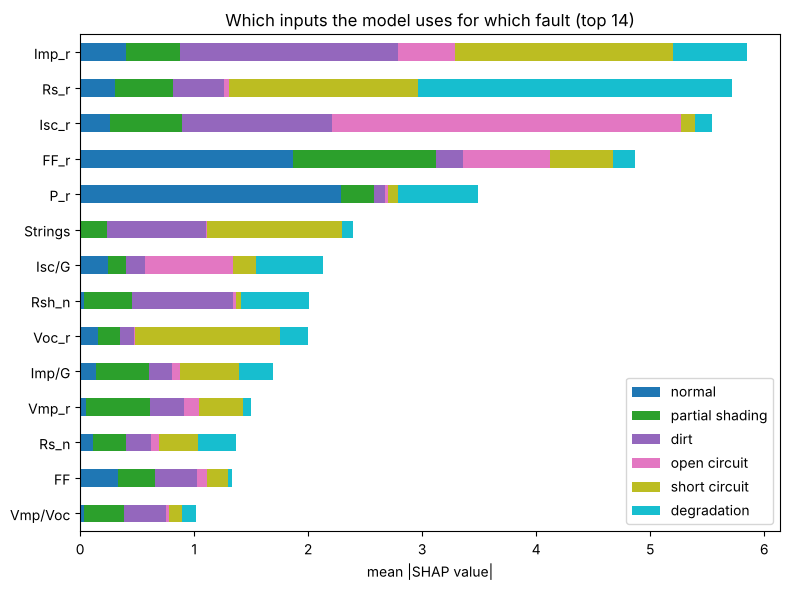

normal           main inputs: P_r, FF_r, Imp_r
partial shading  main inputs: FF_r, Isc_r, Vmp_r
dirt             main inputs: Imp_r, Isc_r, Rsh_n
open circuit     main inputs: Isc_r, Isc/G, FF_r
short circuit    main inputs: Imp_r, Rs_r, Voc_r
degradation      main inputs: Rs_r, P_r, Imp_r



Weather-only model accuracy: 0.170  (guessing = 0.167) -> no weather shortcut


In [10]:
expl = shap.TreeExplainer(source); sv = expl(X0)
imp = pd.DataFrame(np.abs(sv.values).mean(0), index=X0.columns, columns=LABELS)
top = imp.loc[imp.sum(1).sort_values().index[-14:]]
ax = top.plot.barh(stacked=True, figsize=(8, 6), colormap='tab10'); ax.set_xlabel('mean |SHAP value|')
ax.set_title('Which inputs the model uses for which fault (top 14)'); plt.tight_layout(); plt.savefig('figures/shap_importance_by_class.png', dpi=150); plt.show()
for c in LABELS: print(f'{c:16s} main inputs: ' + ', '.join(imp[c].sort_values(ascending=False).index[:3]))
w_only = cross_val_score(XGBClassifier(random_state=0, n_jobs=-1, **PARAMS), LIB[['G/1000', 'AT/50']], y0, cv=GroupKFold(5), groups=LIB.System).mean()
print(f'\nWeather-only model accuracy: {w_only:.3f}  (guessing = {1/K:.3f}) -> no weather shortcut')

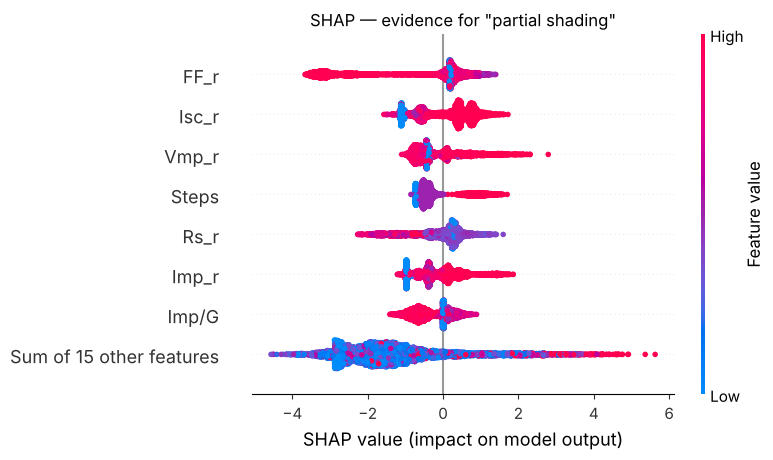

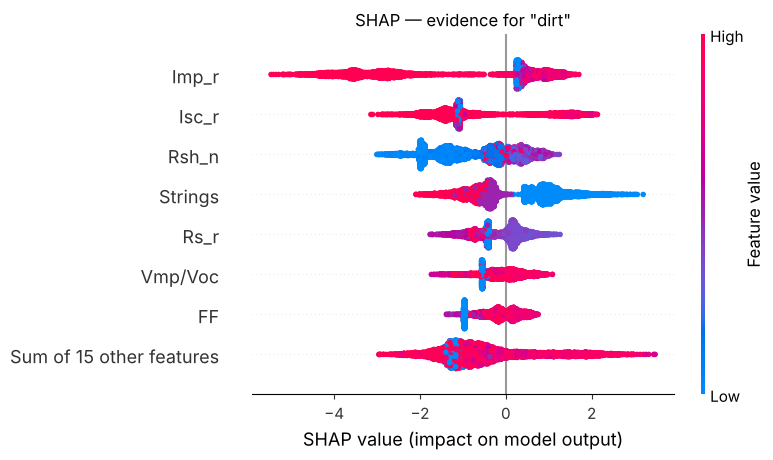

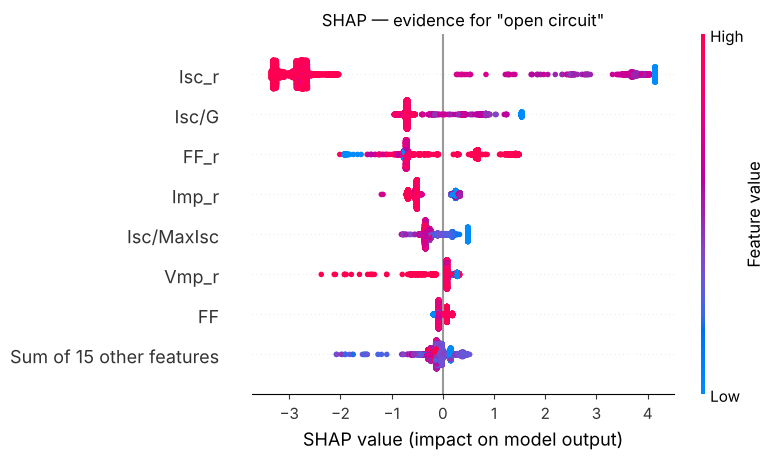

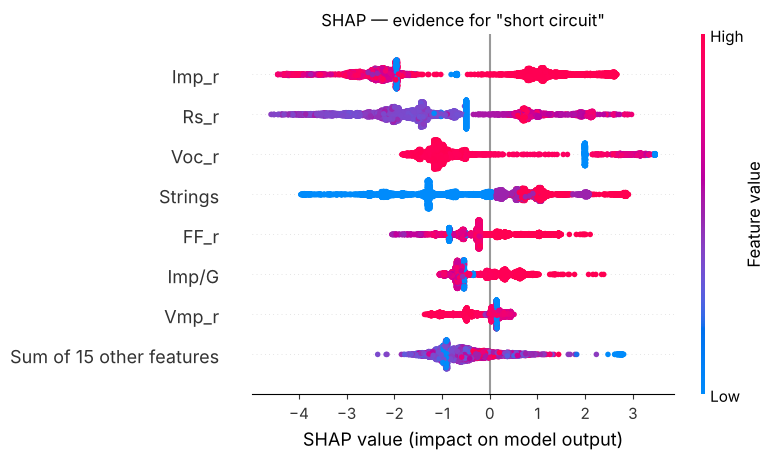

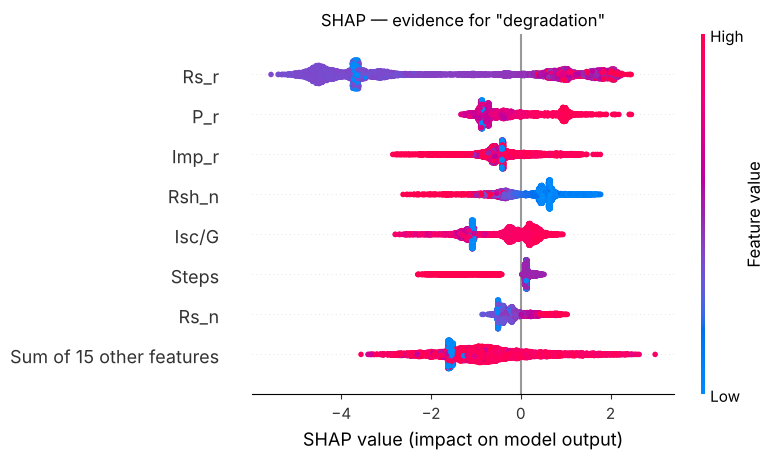

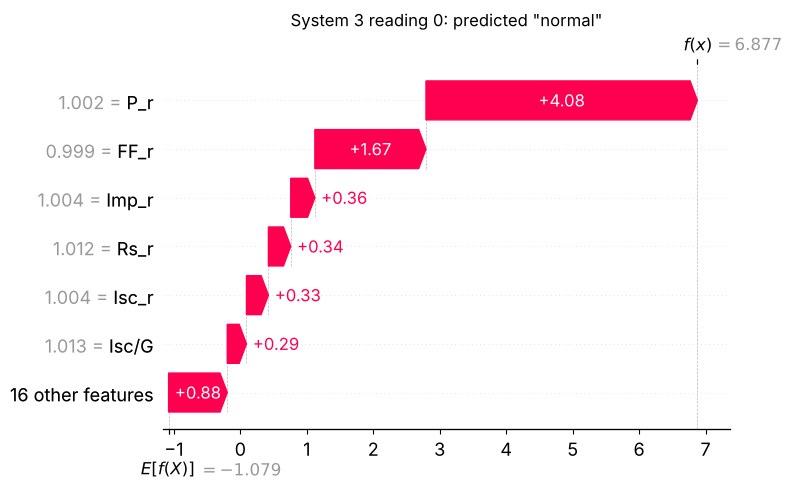

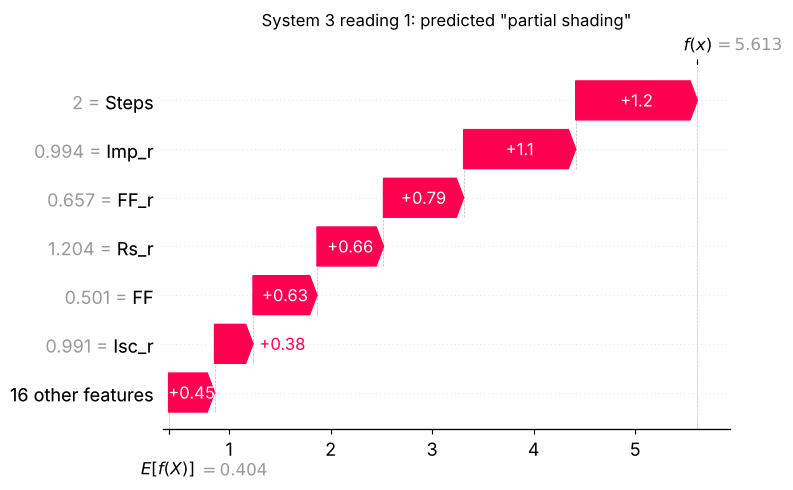

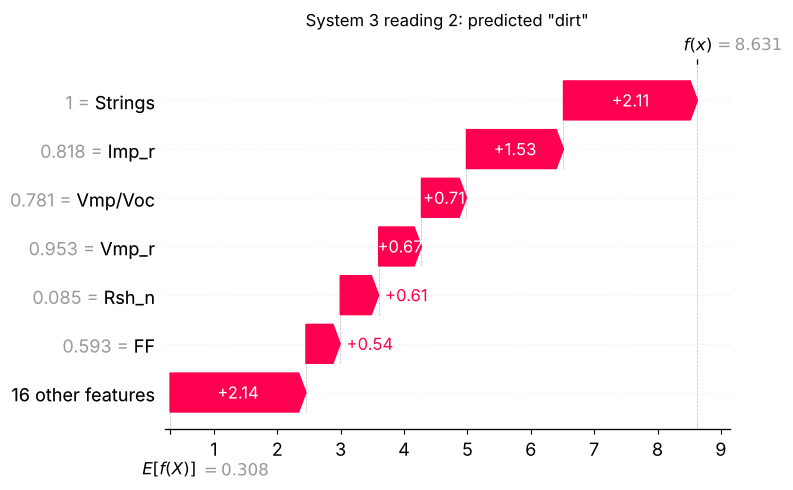

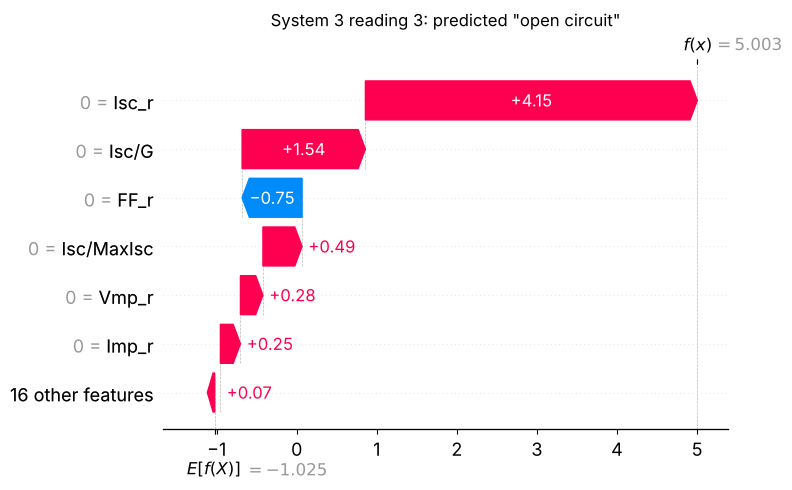

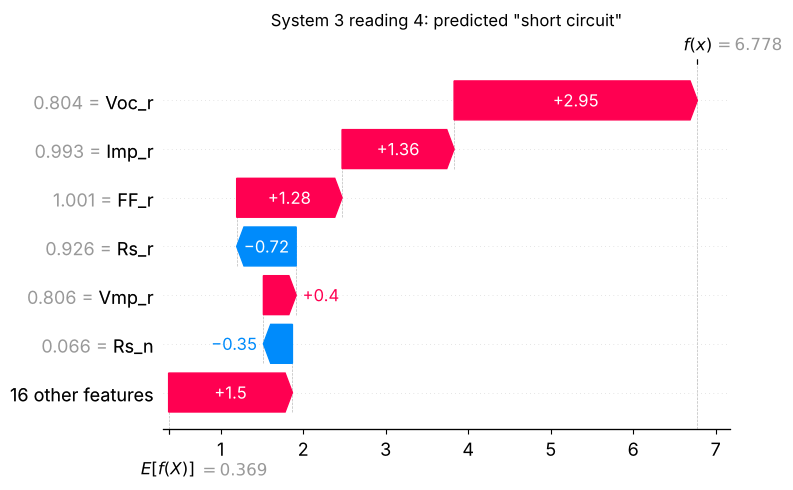

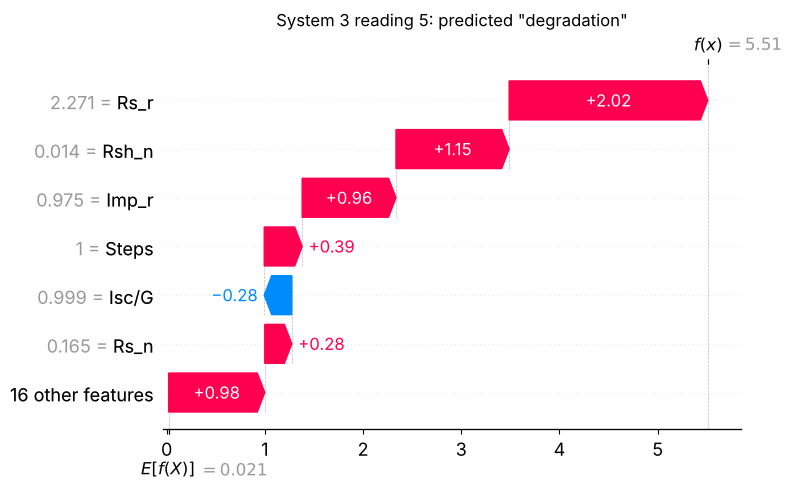

In [11]:
for c in range(1, K):
    shap.plots.beeswarm(sv[:, :, c], max_display=8, show=False)
    plt.title(f'SHAP — evidence for "{LABELS[c]}"'); plt.tight_layout(); plt.savefig(f'figures/shap_beeswarm_{c}.png', dpi=150); plt.show()
X3 = P.inputs(T[3]); sv3 = expl(X3); p3 = source.predict(X3)
for c in range(K):
    i = int(np.where((T[3].Fault == c) & (p3 == c))[0][0])
    shap.plots.waterfall(sv3[i, :, c], max_display=7, show=False)
    plt.title(f'System 3 reading {i}: predicted "{LABELS[c]}"'); plt.tight_layout(); plt.savefig(f'figures/shap_waterfall_{c}.png', dpi=150); plt.show()

## G. Save the models used by the demo / Raspberry Pi program

In [12]:
source.save_model('models/xgb_source.json'); json.dump(PARAMS, open('models/xgb_params.json', 'w'), indent=1)
for s in SYS:     # pre-commissioned models (5 readings per class), same procedure as the demo's Commission button
    shots = T[s].groupby('Fault', group_keys=False).sample(K_SHOTS, random_state=7000 + s)
    XGBClassifier(random_state=0, n_jobs=-1, **PARAMS).fit(pd.concat([X0, P.inputs(shots)]), pd.concat([y0, shots.Fault]),
        sample_weight=np.r_[np.ones(len(X0)), np.full(len(shots), 5.0)]).save_model(f'models/xgb_adapted_system{s}.json')
print(sorted(os.listdir('models')))

['live_model_system2.json', 'xgb_adapted_system1.json', 'xgb_adapted_system2.json', 'xgb_adapted_system3.json', 'xgb_adapted_system4.json', 'xgb_params.json', 'xgb_source.json']


## H. Check any reading yourself\nThe demo's *Export reading* button copies the 22 inputs; paste them here.

In [13]:
def check_reading(values, model_file='models/xgb_source.json'):
    m = XGBClassifier(); m.load_model(model_file); p = m.predict_proba(pd.DataFrame([values])[list(X0.columns)])[0]
    for c in np.argsort(-p)[:3]: print(f'{LABELS[c]:16s} {p[c]:.3f}')
check_reading(P.inputs(T[3].iloc[[4]]).iloc[0].to_dict())

short circuit    1.000
partial shading  0.000
normal           0.000


## Summary

In [14]:
summary = tabA.loc[['zero-shot', 'after 5 readings per class', 'within-system (upper bound)']]
summary.to_csv('results_v6_summary.csv'); print(summary.to_string()); print('\nNOTEBOOK COMPLETE')

                             System 1  System 2  System 3
zero-shot                       0.967     0.980     0.983
after 5 readings per class      0.974     0.992     0.991
within-system (upper bound)     0.987     0.992     0.984

NOTEBOOK COMPLETE
